# The model as a fast level: how sure is each answer

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/07_the_model_as_a_fast_level.ipynb)

Suppose a calculation or a measurement is too expensive to run for every structure. It labels a
few hundred structures. A fitted model then answers for the thousands that are left. The
calculation is the **fine level** and the model is the **fast level**. For this to work the model
must say, for every structure, whether its answer can be used. A bare number does not say that.
It needs two more things:

1. a **standard deviation** in the units of the activity, and a check that it means what it says;
2. a **rule** that sends the doubtful structures back to the fine level.

The third notebook gave conformal intervals, which also say how far a prediction can be trusted.
Here the deviation comes from the Gaussian process that the ridge fit already is. It costs one
extra solve for each structure. The notebook asks four questions.

1. What is the deviation, and is it calibrated, before any test set exists?
2. What does a tolerance rule do with it?
3. Is the deviation worth more than a **constant** deviation, the same for every structure?
4. Does the rule earn more on a set where the hierarchy is real, a crystal property with a
   calculation as the fine level?

The data are three of the eight Sutherland sets of the first notebooks (DHFR, ACE and THER) and
the stored results of `benchmarks/run_surrogate.py`.

Running time: about a minute and a half.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The deviation of one prediction

`prepare_set` and `fit_split` of the benchmark script fit one model on a random 70 % of a set:
the width of the fields and the ridge are chosen by the evidence on the training part, and the
rest of the set is held out. The model then predicts the held-out structures with
`predict_with_sd`.

The variance of the Gaussian process that matches the ridge fit has three parts. One is the
distance of the structure from the training set in the kernel. One is the uncertainty of the
constant level of the activity, which makes a structure far from every training structure
uncertain about the level and not only the shape. One is the noise of a measurement. They are
multiplied by one amplitude, which the evidence gives in closed form from the residuals of the
training set. The square root is in the units of the activity.

=== ACE: 114 molecules


ACE: 114 molecules, 34 held out; width alpha 1 and ridge 0.1 chosen on the training part
the model's own noise level, from the evidence: 0.555; the cross-validated RMSE of the training part: 1.483

test    measured predicted      sd    error       z
10          7.64      6.55    0.67    +1.09   +1.61
33          2.98      3.19    0.71    -0.21   -0.30
71          4.11      2.61    0.77    +1.50   +1.95
24          5.55      5.48    0.77    +0.07   +0.09
82          8.22      6.55    2.16    +1.67   +0.77
113         3.00      4.37    2.26    -1.37   -0.61
89          8.52     10.11    2.33    -1.59   -0.68
7           6.66      9.56    2.36    -2.90   -1.23


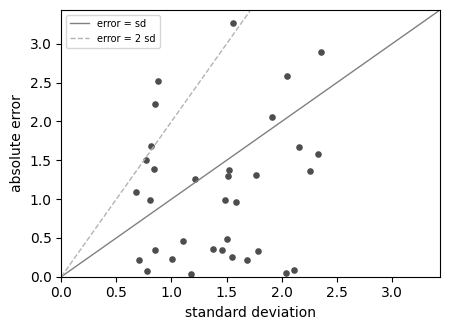

In [2]:
import json
import os
import sys

os.environ["CMF_KERNEL_CACHE"] = "0"
sys.path.insert(0, "benchmarks")

import matplotlib.pyplot as plt
import numpy as np

import run_surrogate as S                   # the sets, the splits, the fits and the scores of MS1
from cmfqsar.surrogate import Calibration, Handoff, tolerance_for_budget

y, mf, cache = S.prepare_set("ACE")
split = S.fit_split(mf, y, cache, 0)
model, te = split["model"], split["te"]
pred, sd = split["pred"], split["sd"]
print("ACE: %d molecules, %d held out; width alpha %g and ridge %g chosen on the training part" % (
    len(y), len(te), split["alpha"], split["lam"]))
print("the model's own noise level, from the evidence: %.3f; the cross-validated RMSE of the training part: %.3f" % (
    model.surrogate().noise_sd, split["rmse_cv"]))
print()
print("%-6s %9s %9s %7s %8s %7s" % ("test", "measured", "predicted", "sd", "error", "z"))
for i in np.argsort(sd)[[0, 1, 2, 3, -4, -3, -2, -1]]:
    print("%-6d %9.2f %9.2f %7.2f %+8.2f %+7.2f" % (te[i], y[te][i], pred[i], sd[i], y[te][i] - pred[i], (y[te][i] - pred[i]) / sd[i]))

err = np.abs(y[te] - pred)
fig, ax = plt.subplots(figsize=(4.6, 3.4))
ax.scatter(sd, err, s=14, color="0.3")
top = max(sd.max(), err.max()) * 1.05
ax.plot([0, top], [0, top], color="0.5", linewidth=1, label="error = sd")
ax.plot([0, top], [0, 2 * top], color="0.7", linewidth=1, linestyle="--", label="error = 2 sd")
ax.set_xlim(0, top)
ax.set_ylim(0, top)
ax.set_xlabel("standard deviation")
ax.set_ylabel("absolute error")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

The first four rows are the structures with the smallest deviation and the last four those with
the largest. The deviations differ by a modest factor. That is a first hint that the deviation
says more about the size of the error than about which structure is the doubtful one.

## Is it calibrated?

The **standardised residual** is z = (measured - predicted) / sd. For a deviation that means what
it says, the root mean square of z is one, and two standard deviations hold about 95 % of the
activities. The program reports both on the folds of the training part, before any test set
exists (`model.calibration()`, or `cmf build --calibration`), and on held-out structures. A root
mean square above one says that the model is surer than it should be. The factor that would
make it one is reported and is not applied.

The cell fits five splits of each of three sets and prints the calibration on the folds, on the
held-out structures, and the share inside two standard deviations.

In [3]:
sets = ["DHFR", "ACE", "THER"]
prepared = {"ACE": (y, mf, cache)}
splits = {}
for name in sets:
    if name not in prepared:
        prepared[name] = S.prepare_set(name)
    yy, mm, cc = prepared[name]
    splits[name] = [S.fit_split(mm, yy, cc, rep) for rep in range(5)]

print()
print("%-6s %4s %10s %12s %12s %12s %12s" % ("set", "n", "test RMSE", "mean sd", "z rms folds", "z rms test", "inside 2 sd"))
for name in sets:
    yy = prepared[name][0]
    held = [Calibration.of(yy[s["te"]], s["pred"], s["sd"]) for s in splits[name]]
    print("%-6s %4d %10.3f %12.3f %12.2f %12.2f %11.0f%%" % (
        name, len(yy), np.mean([h.rmse for h in held]), np.mean([h.mean_sd for h in held]),
        np.mean([s["folds"].z_rms for s in splits[name]]), np.mean([h.z_rms for h in held]),
        100 * np.mean([h.coverage_2sd for h in held])))

=== DHFR: 361 molecules


=== THER: 76 molecules



set       n  test RMSE      mean sd  z rms folds   z rms test  inside 2 sd
DHFR    361      0.751        0.679         1.10         1.08          93%
ACE     114      1.512        1.378         0.99         1.15          89%
THER     76      1.635        1.605         1.03         1.07          93%


The root mean square of z on the folds of the training part is 1.10, 0.99 and 1.03. It is close to
one before any test set has been used. On the held-out structures it is 1.08, 1.15 and 1.07, a
little above one, so the model is slightly surer than it should be. ACE is the furthest, with 1.15
and 89 % inside two deviations. The mean deviation is within 10 % of the RMSE on every set (0.679
against 0.751 for DHFR, 1.378 against 1.512 for ACE, 1.605 against 1.635 for THER). The scale of
the deviation comes from the residuals of the training set alone, and it is the right size.

## A number is not a decision: the tolerance rule

A **tolerance**, in the units of the activity, turns the deviation into a decision. Every
structure whose deviation is above the tolerance goes back to the fine level. The natural
tolerance is the error the model claims for a typical structure, its cross-validated RMSE. The
other way round, `tolerance_for_budget` gives the tolerance that sends exactly the share of the
structures that the fine level can afford. `Handoff.of` reports what the rule did, with the error
on each side because the activities of the held-out structures are known here.

In [4]:
print("%-6s %10s %9s %15s %15s | %24s" % ("set", "tolerance", "answered", "RMSE answered", "RMSE deferred", "25 % sent back: answered, sent"))
for name in sets:
    yy = prepared[name][0]
    rows = []
    for s in splits[name]:
        te_, pr_, sd_ = s["te"], s["pred"], s["sd"]
        rule = Handoff.of(sd_, s["rmse_cv"], y=yy[te_], mean=pr_)
        budget = Handoff.of(sd_, tolerance_for_budget(sd_, 0.25), y=yy[te_], mean=pr_)
        rows.append([s["rmse_cv"], (rule.n - rule.n_deferred) / rule.n, rule.rmse_answered, rule.rmse_deferred,
                     budget.rmse_answered, budget.rmse_deferred])
    m = np.nanmean(np.array(rows), axis=0)
    print("%-6s %10.3f %8.0f%% %15.3f %15.3f | %12.3f %11.3f" % (name, m[0], 100 * m[1], m[2], m[3], m[4], m[5]))
print()
rule = Handoff.of(sd, split["rmse_cv"], y=y[te], mean=pred)
print("ACE split 0 in words:", rule.describe())

set     tolerance  answered   RMSE answered   RMSE deferred | 25 % sent back: answered, sent
DHFR        0.805       80%           0.678           0.989 |        0.671       0.944
ACE         1.380       56%           1.451           1.557 |        1.408       1.728
THER        1.551       50%           1.721           1.596 |        1.633       1.564

ACE split 0 in words: tolerance 1.483: the model answers 16 of 34 (47%), 18 go to the fine level; RMSE of the answered 1.193 (mean sd 0.956), of the deferred 1.580 (mean sd 1.841)


On DHFR the model answers 80 % of the held-out structures at an RMSE of 0.678 and defers the rest,
whose RMSE is 0.989. On ACE the answered 56 % have 1.451 and the deferred 1.557, which is a
difference of 7 %. On THER the order is reversed: the answered half has an RMSE of 1.721 and the
deferred half 1.596. Sending back a fixed quarter gives the same picture. The last line shows the
rule for one split of ACE in words.

So what the rule gives is a **fair size** of the error for the answered share. It is not a sharp
separation of the good predictions from the bad ones. On a series of related molecules the
deviation changes little from one structure to the next, and so does the error it can announce.

## Is the deviation worth more than a constant one?

A deviation that is right on average can still say little about which structure is the doubtful
one. The reference is the deviation that a user has without any model of it: the cross-validated
RMSE of the training part, the same for every structure. It is calibrated on average by
construction. The two are scored by the negative log density that each gives to the measured
activities of the held-out structures. This is a **proper scoring rule**: it is smallest for the
deviation that is true. It is in nats per structure, and smaller is better. It rewards a deviation
that is small where the model is right and large where it is wrong.

The held-out structures are also cut into three equal groups by their deviation. A deviation
that orders the errors well has the same root mean square of z in all three groups.

In [5]:
print("%-6s %18s %22s %8s" % ("set", "score, the model", "score, the constant", "gain"))
scores = {}
for name in sets:
    yy = prepared[name][0]
    rows = [S.score_split(yy[s["te"]] - s["pred"], s["sd"], s["rmse_cv"]) for s in splits[name]]
    scores[name] = rows
    m, c = np.mean([r["model"]["nlpd"] for r in rows]), np.mean([r["constant"]["nlpd"] for r in rows])
    print("%-6s %18.3f %22.3f %+8.3f" % (name, m, c, c - m))

print()
print("the three sets together, in thirds of the deviation (lowest, middle, highest):")
for b, label in enumerate(["lowest", "middle", "highest"]):
    n = sum(r["bins"][b]["n"] for rows in scores.values() for r in rows)
    sd_b = sum(r["bins"][b]["sum_sd"] for rows in scores.values() for r in rows) / n
    e2 = sum(r["bins"][b]["sum_err2"] for rows in scores.values() for r in rows) / n
    z2 = sum(r["bins"][b]["sum_z2"] for rows in scores.values() for r in rows) / n
    print("   %-8s %4d structures, mean sd %.3f, RMSE %.3f, z rms %.2f" % (label, n, sd_b, np.sqrt(e2), np.sqrt(z2)))

set      score, the model    score, the constant     gain
DHFR                1.081                  1.140   +0.059
ACE                 1.887                  1.865   -0.023
THER                1.972                  1.949   -0.023

the three sets together, in thirds of the deviation (lowest, middle, highest):
   lowest    280 structures, mean sd 0.771, RMSE 1.080, z rms 1.17
   middle    275 structures, mean sd 0.903, RMSE 0.999, z rms 1.10
   highest   270 structures, mean sd 1.189, RMSE 1.231, z rms 1.02


For these three sets the deviation of the model beats the constant one on DHFR (+0.059 nats) and
loses on ACE and THER (-0.023 each). In thirds of the deviation, the root mean square of z is 1.17,
1.10 and 1.02. It falls as the deviation grows, so the structures with the smallest deviation are
the ones where the model is surest, and a little too sure. The RMSE does not rise from the lowest
to the middle third (1.080 and 0.999), and it rises to 1.231 in the highest. Three sets are few.

All eight sets, from the stored results of `python benchmarks/run_surrogate.py --reference`:

In [6]:
print(S.report_reference(S.RESULTS).split("## A constant deviation as the reference, and the calibration in bins of the deviation")[1].strip())

The same 8 sets and 5 splits. The reference gives every held-out structure the cross-validated RMSE of the training part as its deviation. The score is the negative log density that a Gaussian of that deviation gives to the measured activity, in nats per structure (smaller is better; it rewards a deviation that is right and one that is small where the model is right). The gain is the constant's score minus the model's, so a positive gain means that the deviation of the model is worth more.

| set | n | score of the model | score of the constant | gain | z rms, model | z rms, constant | inside 2 sd, model | inside 2 sd, constant |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| DHFR | 361 | 1.081 | 1.140 | +0.059 | 1.08 | 0.94 | 93% | 96% |
| COX2 | 282 | 1.217 | 1.222 | +0.005 | 0.99 | 1.02 | 93% | 93% |
| BZR | 147 | 0.944 | 0.972 | +0.028 | 0.98 | 0.96 | 94% | 96% |
| ACE | 114 | 1.887 | 1.865 | -0.023 | 1.15 | 1.11 | 89% | 93% |
| AChE | 111 | 1.152 | 1.229 | +0.077 | 0.96 | 0.94 | 

Over all eight sets, the deviation of the model is ahead of the constant one by +0.034 nats per
structure [+0.005, +0.061], and on 6 of the 8 sets. The gain is small, and its interval is only
just clear of zero. ACE and THER, where the tolerance rule also failed, are the two sets where the
constant wins.

In thirds of the deviation, z rms is 1.06, 1.07 and 1.03, so the deviation is calibrated within
each third. The RMSE rises from 0.85 to 0.87 to 1.06 as the mean deviation goes from 0.70 to 0.80 to
1.03. So the deviation does order the errors, mildly. The constant deviation is not a straw man. It is
calibrated on average by construction and has the same share inside two deviations (93 %). What the
deviation that depends on the structure adds is a small, real gain in the score, and not a sharp
ordering.

## Where the hierarchy is real: a barrier with a calculation as the fine level

The Sutherland sets are series of related molecules. The case the module is made for is
different: 1,801 hops of lithium ions in 393 crystals, from the sample of the hop notebook, each
labelled by a bond-valence calculation, which is the fine level here. The folds hold out whole
structures. The next cell reads the stored result for the model with a Gaussian kernel and with
a linear kernel.

In [7]:
hops = json.load(open(os.path.join(S.RESULTS, "litraj.json")))
print("%d hops in %d structures; barriers have a standard deviation of %.2f eV; folds hold out whole structures" % (
    hops["n"], hops["n_structures"], hops["y_sd"]))
print()
print("%-9s %7s %9s %10s %12s %11s %9s" % ("kernel", "q2", "RMSE, eV", "mean sd", "z rms, held", "inside 2sd", "rho"))
for label, a in hops["arms"].items():
    print("%-9s %+7.3f %9.3f %10.3f %12.2f %10.0f%% %+9.2f" % (label, a["q2"], a["test"]["rmse"], a["test"]["mean_sd"],
          a["test"]["z_rms"], 100 * a["test"]["coverage_2sd"], a["test"]["spearman"]))
print()
print("the tolerance rule, with the tolerance at the claimed error of the training part:")
print("%-9s %10s %9s %15s %15s" % ("kernel", "tolerance", "answered", "RMSE answered", "RMSE deferred"))
for label, a in hops["arms"].items():
    r = a["rule"]
    print("%-9s %10.3f %8.0f%% %15.3f %15.3f" % (label, r["tolerance"], 100 * (r["n"] - r["n_deferred"]) / r["n"], r["rmse_answered"], r["rmse_deferred"]))

1801 hops in 393 structures; barriers have a standard deviation of 1.90 eV; folds hold out whole structures

kernel         q2  RMSE, eV    mean sd  z rms, held  inside 2sd       rho
linear     +0.572     1.246      1.136         1.05         95%     +0.20
Gaussian   +0.623     1.169      1.053         0.99         96%     +0.35

the tolerance rule, with the tolerance at the claimed error of the training part:
kernel     tolerance  answered   RMSE answered   RMSE deferred
linear         1.242       87%           1.123           1.856
Gaussian       1.207       82%           0.998           1.752


The deviation is calibrated for both kernels here (z rms 1.05 and 0.99, with 95 % and 96 % inside
two deviations), and it orders the errors better than on the Sutherland sets: the rank correlation
with the error is +0.20 and +0.35, against +0.14. The rule separates by a factor of 1.7 to 1.8. The
Gaussian kernel answers 82 % of the hops at 1.00 eV and sends back 18 % whose RMSE is 1.75 eV, and
the linear kernel answers 87 % at 1.12 eV against 1.86 eV for the rest.

A likely reason is the data and not the method. A held-out structure is often the only one of its
chemical system, so its distance from the training set carries real information. In a series of
related molecules the distances differ little.

## Without the full kernel: the low-rank path

A model fitted in the space of its landmarks never builds the n by n kernel, so that it can be
trained on very many structures. Its deviation is read from the small matrix of the landmarks.
The stored result below takes every training molecule as a landmark (which reproduces the exact
kernel), and then half and a quarter of them. It gives the mean over the eight sets of the root
mean square of z on the held-out structures and the largest difference from the exact path.

In [8]:
import glob

lowrank = [json.load(open(f)) for f in sorted(glob.glob(os.path.join(S.RESULTS, "lowrank_*.json")))]
print("%-10s %12s %12s %24s" % ("landmarks", "z rms, test", "exact path", "largest difference of z rms"))
for kind in ("molecules", "half", "quarter"):
    z_arm = [np.mean([r["arms"][kind]["test"]["z_rms"] for r in d["rows"]]) for d in lowrank]
    z_ex = [np.mean([r["exact"]["test"]["z_rms"] for r in d["rows"]]) for d in lowrank]
    worst = max(abs(r["arms"][kind]["test"]["z_rms"] - r["exact"]["test"]["z_rms"]) for d in lowrank for r in d["rows"])
    print("%-10s %12.2f %12.2f %24.2g" % (kind, np.mean(z_arm), np.mean(z_ex), worst))

landmarks   z rms, test   exact path largest difference of z rms
molecules          1.05         1.05                  1.1e-08
half               0.94         1.05                      0.6
quarter            0.82         1.05                      1.2


With every training molecule as a landmark, the deviation equals the exact one to rounding (the
largest difference of z rms is 1.1e-08). With half or a quarter of the molecules the model is
another model. Its z rms falls to 0.94 and 0.82, below one, so its deviation is larger than the
error. It is conservative by construction: one term keeps the variance from falling to zero where
the landmarks span nothing. The largest differences from the exact path are 0.6 and 1.2 on single
splits, from the smallest sets. The gate of item MS6, within 0.1, holds only when all the
molecules are landmarks.

## What this shows and what it does not

**What it shows.**

- A fitted model can state a standard deviation in the units of the activity. It is calibrated on
  the folds of the training part, before any test set exists: z rms 0.99 to 1.10 on the three sets
  here.
- On eight sets the deviation is calibrated within thirds of the deviation too (z rms 1.03 to
  1.07), it orders the errors mildly, and it beats a constant deviation by +0.034 nats per
  structure [+0.005, +0.061], on 6 of 8 sets.
- A tolerance rule gives the answered share a fair size of the error. On eight sets it answers 61 %
  at an RMSE of 0.90 against 1.03 for the deferred share.
- Where the hierarchy is real, a crystal property with a calculation as the fine level, the same
  rule separates by a factor of 1.7 to 1.8.

**What it does not show.**

- That the rule picks out the bad predictions in a series of related molecules. On THER the
  deferred half is predicted better than the answered half.
- That a constant deviation is not good enough there. The gain is 0.034 nats, just clear of zero,
  and two of the eight sets lose.
- How the deviation behaves where the kernel misses a part of the chemistry. These sets are well
  described by the fields, so the factor stays near one. A kernel that misses something would
  show a root mean square of z above one, and the program reports it.
- A calibrated deviation on the low-rank path with few landmarks. It is conservative, not
  calibrated.

The deviation is a fair statement of how large the error is. It is a weak statement of which
structure is wrong.